# Amazon Fine Food Reviews - MongoDB Homework
## Sistemi Informativi Evoluti e Big Data - A.A. 2025-2026

Questo notebook implementa l'analisi completa del dataset [Amazon Fine Food Reviews](https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews) utilizzando MongoDB.

### Struttura del lavoro:
1. **Caricamento dei dati** - Importazione e organizzazione in collezioni per score
2. **Sentiment Analysis** - Analisi del sentiment usando VADER
3. **Interrogazioni Analitiche** - Query e visualizzazioni
4. **Sistema di Raccomandazione** - Algoritmo di suggerimento prodotti
5. **Analisi Avanzata** - Evoluzione del sentiment nel tempo

## Setup - Installazione delle librerie necessarie

In [64]:
# Importazione delle librerie necessarie
import pandas as pd
import numpy as np
from pymongo import MongoClient
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from collections import defaultdict
import time
import warnings
warnings.filterwarnings('ignore')

# Configurazione visualizzazioni
# plt.style.use('seaborn-v0_8-darkgrid')
# sns.set_palette("husl")
# %matplotlib inline

## 1. Caricamento dei Dati

Carichiamo il dataset e lo organizziamo in collezioni separate per ogni livello di score (1-5) e una collezione per i record senza testo.

In [65]:
# Connessione a MongoDB
client = MongoClient('mongodb://localhost:27017/')
db = client['amazon_food_reviews']

# Elimina collezioni esistenti per ricominciare da zero
collections_to_drop = ['score_1', 
                        'score_2', 
                        'score_3', 
                        'score_4', 
                        'score_5', 
                        'no_text']
for col in collections_to_drop:
    db[col].drop()

print("Connesso a MongoDB")
print(f"Database: {db.name}")

Connesso a MongoDB
Database: amazon_food_reviews


### 🛡️ Schema Validation con MongoDB Validators

MongoDB permette di definire **validatori** a livello di collezione per garantire l'integrità dei dati. Utilizziamo il **JSON Schema** per:
- ✅ Validare tipi di dati
- ✅ Imporre campi obbligatori
- ✅ Definire range di valori ammessi
- ✅ Validare formati (email, date, etc.)

**Vantaggi:**
- 🔒 Robustezza dei dati garantita da MongoDB stesso
- 🚫 Rigetto automatico di documenti non validi
- 📝 Documentazione implicita dello schema
- ⚡ Performance migliori rispetto a validazione Python

In [ ]:
# Definizione dello schema di validazione per le collezioni di review
review_validator = {
    '$jsonSchema': {
        'bsonType': 'object',
        'required': ['Id', 'ProductId', 'UserId', 'Score', 'Time'],
        'properties': {
            'Id': {
                'bsonType': 'int',
                'description': 'ID univoco della review - obbligatorio e deve essere intero'
            },
            'ProductId': {
                'bsonType': 'string',
                'minLength': 1,
                'maxLength': 100,
                'description': 'ID del prodotto - obbligatorio, stringa non vuota'
            },
            'UserId': {
                'bsonType': 'string',
                'minLength': 1,
                'maxLength': 100,
                'description': 'ID utente - obbligatorio, stringa non vuota'
            },
            'ProfileName': {
                'bsonType': ['string', 'null'],
                'maxLength': 200,
                'description': 'Nome profilo utente - opzionale'
            },
            'HelpfulnessNumerator': {
                'bsonType': ['int', 'null'],
                'minimum': 0,
                'description': 'Numeratore helpfulness - opzionale, se presente >= 0'
            },
            'HelpfulnessDenominator': {
                'bsonType': ['int', 'null'],
                'minimum': 0,
                'description': 'Denominatore helpfulness - opzionale, se presente >= 0'
            },
            'Score': {
                'bsonType': 'int',
                'minimum': 1,
                'maximum': 5,
                'description': 'Rating prodotto - obbligatorio, range 1-5'
            },
            'Time': {
                'bsonType': 'int',
                'minimum': 0,
                'description': 'Unix timestamp - obbligatorio, deve essere positivo'
            },
            'Summary': {
                'bsonType': ['string', 'null'],
                'maxLength': 500,
                'description': 'Sommario review - opzionale'
            },
            'Text': {
                'bsonType': ['string', 'null'],
                'description': 'Testo completo review - opzionale'
            },
            'sentiment': {
                'bsonType': ['string', 'null'],
                'enum': ['positive', 'neutral', 'negative', None],
                'description': 'Sentiment analizzato - opzionale, valori ammessi'
            },
            'compound_score': {
                'bsonType': ['double', 'null'],
                'minimum': -1.0,
                'maximum': 1.0,
                'description': 'Score VADER - opzionale, range [-1, 1]'
            }
        }
    }
}

# Schema per collezione no_text (documenti senza testo)
no_text_validator = {
    '$jsonSchema': {
        'bsonType': 'object',
        'required': ['Id', 'ProductId', 'UserId', 'Score', 'Time'],
        'properties': {
            'Id': {'bsonType': 'int'},
            'ProductId': {'bsonType': 'string', 'minLength': 1},
            'UserId': {'bsonType': 'string', 'minLength': 1},
            'ProfileName': {'bsonType': ['string', 'null']},
            'HelpfulnessNumerator': {'bsonType': ['int', 'null'], 'minimum': 0},
            'HelpfulnessDenominator': {'bsonType': ['int', 'null'], 'minimum': 0},
            'Score': {'bsonType': 'int', 'minimum': 1, 'maximum': 5},
            'Time': {'bsonType': 'int', 'minimum': 0},
            'Summary': {'bsonType': ['string', 'null']}
        }
    }
}

print("✅ Schema di validazione definito con successo!")
print("\n📋 Regole di validazione principali:")
print("   • Campi obbligatori: Id, ProductId, UserId, Score, Time")
print("   • Score deve essere tra 1 e 5")
print("   • Time deve essere >= 0 (Unix timestamp)")
print("   • Sentiment può essere solo: positive, neutral, negative")
print("   • Compound score deve essere tra -1.0 e 1.0")
print("   • ProductId e UserId non possono essere stringhe vuote")

In [ ]:
# Creazione/ricreazione delle collezioni con validatori
print("🔧 Configurazione collezioni con validatori...\n")

collections_config = [
    ('score_1', review_validator),
    ('score_2', review_validator),
    ('score_3', review_validator),
    ('score_4', review_validator),
    ('score_5', review_validator),
    ('no_text', no_text_validator)
]

for coll_name, validator in collections_config:
    # Elimina collezione se esiste
    if coll_name in db.list_collection_names():
        db[coll_name].drop()
        print(f"   🗑️  Eliminata collezione esistente: {coll_name}")
    
    # Crea nuova collezione con validator
    db.create_collection(
        coll_name,
        validator=validator,
        validationLevel='strict',      # Valida tutti i documenti (insert + update)
        validationAction='error'       # Rigetta documenti non validi
    )
    print(f"   ✅ Creata collezione {coll_name} con validazione strict")

print("\n" + "="*70)
print("🛡️  VALIDAZIONE ATTIVA SU TUTTE LE COLLEZIONI")
print("="*70)
print("\n💡 Comportamento:")
print("   • validationLevel='strict' → valida sia INSERT che UPDATE")
print("   • validationAction='error' → rigetta documenti non conformi")
print("   • I documenti invalidi NON verranno inseriti nel database")
print("   • MongoDB restituirà errore dettagliato per ogni violazione")

In [ ]:
# Caricamento del dataset CSV
print("Caricamento del dataset...")
df = pd.read_csv('Reviews.csv')

print(f"Dataset caricato: {len(df)} recensioni")
print(f"\nColonne disponibili: {list(df.columns)}")

Caricamento del dataset...
Dataset caricato: 568454 recensioni
Dataset caricato: 568454 recensioni


In [ ]:
# Preparazione e inserimento dei dati in MongoDB con validazione
def prepare_document(row):
    """
    Prepara un documento MongoDB dalla riga del DataFrame.
    I documenti devono rispettare lo schema di validazione definito.
    """
    # Campi obbligatori con validazione
    doc = {
        'Id': int(row['Id']),
        'ProductId': str(row['ProductId']).strip(),
        'UserId': str(row['UserId']).strip(),
        'Score': int(row['Score']),
        'Time': int(row['Time'])
    }
    
    # Campi opzionali - aggiunti solo se validi
    if pd.notna(row['ProfileName']) and str(row['ProfileName']).strip():
        doc['ProfileName'] = str(row['ProfileName'])[:200]  # Max 200 caratteri
    
    if pd.notna(row['HelpfulnessNumerator']):
        doc['HelpfulnessNumerator'] = max(0, int(row['HelpfulnessNumerator']))
    
    if pd.notna(row['HelpfulnessDenominator']):
        doc['HelpfulnessDenominator'] = max(0, int(row['HelpfulnessDenominator']))
    
    if pd.notna(row['Summary']) and str(row['Summary']).strip():
        doc['Summary'] = str(row['Summary'])[:500]  # Max 500 caratteri
    
    if pd.notna(row['Text']) and str(row['Text']).strip():
        doc['Text'] = str(row['Text'])
    
    return doc

# Organizzazione dei documenti per collezione con gestione errori di validazione
print("📦 Organizzazione dei dati in collezioni con validazione...\n")

# Statistiche di caricamento
stats = {
    'inserted': {f'score_{i}': 0 for i in range(1, 6)},
    'validation_errors': 0,
    'invalid_documents': []
}
stats['inserted']['no_text'] = 0

batch_size = 1000
batches = {f'score_{i}': [] for i in range(1, 6)}
batches['no_text'] = []

start_time = time.time()  # Inizio misurazione tempo

from pymongo.errors import BulkWriteError

for idx, row in df.iterrows():
    try:
        doc = prepare_document(row)
        
        # Determina la collezione di destinazione
        has_text = ('Text' in doc and doc['Text']) or ('Summary' in doc and doc['Summary'])
        
        if not has_text:
            collection_name = 'no_text'
        else:
            collection_name = f"score_{doc['Score']}"
        
        batches[collection_name].append(doc)
        
        # Insert batch quando raggiunge la dimensione specificata
        if len(batches[collection_name]) >= batch_size:
            try:
                db[collection_name].insert_many(batches[collection_name], ordered=False)
                stats['inserted'][collection_name] += len(batches[collection_name])
            except BulkWriteError as bwe:
                # Alcuni documenti inseriti, alcuni falliti
                stats['inserted'][collection_name] += bwe.details['nInserted']
                stats['validation_errors'] += len(bwe.details['writeErrors'])
                for error in bwe.details['writeErrors'][:3]:  # Salva primi 3 errori
                    stats['invalid_documents'].append({
                        'index': error['index'],
                        'error': error['errmsg'][:100]  # Primi 100 caratteri
                    })
            batches[collection_name] = []
        
        if (idx + 1) % 50000 == 0:
            print(f"   ⏳ Processate {idx + 1:,} recensioni...")
    
    except Exception as e:
        stats['validation_errors'] += 1
        if len(stats['invalid_documents']) < 5:
            stats['invalid_documents'].append({
                'row': idx,
                'error': str(e)[:100]
            })

# Inserisci i batch rimanenti
for collection_name, docs in batches.items():
    if docs:
        try:
            db[collection_name].insert_many(docs, ordered=False)
            stats['inserted'][collection_name] += len(docs)
        except BulkWriteError as bwe:
            stats['inserted'][collection_name] += bwe.details['nInserted']
            stats['validation_errors'] += len(bwe.details['writeErrors'])

end_time = time.time()  # Fine misurazione tempo
elapsed = end_time - start_time

print("\n" + "="*70)
print("📊 RIEPILOGO CARICAMENTO DATI CON VALIDAZIONE")
print("="*70)
print("\n✅ Documenti inseriti con successo:")
for col, count in sorted(stats['inserted'].items()):
    print(f"   {col:15s}: {count:7,d} documenti")
print("   " + "-"*50)
print(f"   TOTALE:         {sum(stats['inserted'].values()):7,d} documenti")

if stats['validation_errors'] > 0:
    print(f"\n⚠️  Errori di validazione: {stats['validation_errors']:,d}")
    print("\n❌ Esempi di documenti non validi:")
    for doc_err in stats['invalid_documents'][:5]:
        print(f"   • {doc_err}")
else:
    print("\n✅ Nessun errore di validazione - tutti i documenti sono conformi allo schema!")

print(f"\n⏱️  Tempo di esecuzione: {elapsed:.2f} secondi ({elapsed/60:.2f} minuti)")
print(f"📈 Throughput: {sum(stats['inserted'].values())/elapsed:.0f} documenti/secondo")
print("="*70)

Organizzazione dei dati in collezioni...
Processate 10000 recensioni...
Processate 10000 recensioni...
Processate 20000 recensioni...
Processate 20000 recensioni...
Processate 30000 recensioni...
Processate 30000 recensioni...
Processate 40000 recensioni...
Processate 40000 recensioni...
Processate 50000 recensioni...
Processate 50000 recensioni...
Processate 60000 recensioni...
Processate 60000 recensioni...
Processate 70000 recensioni...
Processate 70000 recensioni...
Processate 80000 recensioni...
Processate 80000 recensioni...
Processate 90000 recensioni...
Processate 90000 recensioni...
Processate 100000 recensioni...
Processate 100000 recensioni...
Processate 110000 recensioni...
Processate 110000 recensioni...
Processate 120000 recensioni...
Processate 120000 recensioni...
Processate 130000 recensioni...
Processate 130000 recensioni...
Processate 140000 recensioni...
Processate 140000 recensioni...
Processate 150000 recensioni...
Processate 150000 recensioni...
Processate 160000

### 🧪 Test del Sistema di Validazione

Prima di caricare i dati reali, testiamo il validatore con documenti validi e non validi per verificare che funzioni correttamente.

In [ ]:
print("🧪 Test del sistema di validazione MongoDB\n")

# Test 1: Documento VALIDO
print("Test 1: Documento VALIDO")
valid_doc = {
    'Id': 1,
    'ProductId': 'B001E4KFG0',
    'UserId': 'A3SGXH7AUHU8GW',
    'Score': 5,
    'Time': 1303862400,
    'Summary': 'Good Quality Dog Food',
    'Text': 'I have bought several of the Vitality canned dog food products...'
}

try:
    result = db.score_5.insert_one(valid_doc)
    print(f"   ✅ SUCCESSO: Documento inserito con ID {result.inserted_id}")
    db.score_5.delete_one({'_id': result.inserted_id})  # Pulizia
except Exception as e:
    print(f"   ❌ ERRORE: {str(e)[:100]}")

# Test 2: Score INVALIDO (fuori range 1-5)
print("\nTest 2: Score INVALIDO (Score = 10, ammesso solo 1-5)")
invalid_score = valid_doc.copy()
invalid_score['Id'] = 2
invalid_score['Score'] = 10

try:
    result = db.score_5.insert_one(invalid_score)
    print(f"   ❌ PROBLEMA: Documento inserito (non dovrebbe!)")
except Exception as e:
    print(f"   ✅ CORRETTO: Validazione ha bloccato l'inserimento")
    print(f"   📝 Motivo: {str(e)[:150]}")

# Test 3: Campo OBBLIGATORIO mancante (UserId)
print("\nTest 3: Campo OBBLIGATORIO mancante (UserId)")
missing_field = valid_doc.copy()
missing_field['Id'] = 3
del missing_field['UserId']

try:
    result = db.score_5.insert_one(missing_field)
    print(f"   ❌ PROBLEMA: Documento inserito (non dovrebbe!)")
except Exception as e:
    print(f"   ✅ CORRETTO: Validazione ha bloccato l'inserimento")
    print(f"   📝 Motivo: {str(e)[:150]}")

# Test 4: Tipo di dato ERRATO (Score come stringa invece di int)
print("\nTest 4: Tipo di dato ERRATO (Score come stringa)")
wrong_type = valid_doc.copy()
wrong_type['Id'] = 4
wrong_type['Score'] = "5"  # Stringa invece di int

try:
    result = db.score_5.insert_one(wrong_type)
    print(f"   ❌ PROBLEMA: Documento inserito (non dovrebbe!)")
except Exception as e:
    print(f"   ✅ CORRETTO: Validazione ha bloccato l'inserimento")
    print(f"   📝 Motivo: {str(e)[:150]}")

# Test 5: ProductId VUOTO (minLength = 1)
print("\nTest 5: ProductId VUOTO (deve avere minLength=1)")
empty_string = valid_doc.copy()
empty_string['Id'] = 5
empty_string['ProductId'] = ""

try:
    result = db.score_5.insert_one(empty_string)
    print(f"   ❌ PROBLEMA: Documento inserito (non dovrebbe!)")
except Exception as e:
    print(f"   ✅ CORRETTO: Validazione ha bloccato l'inserimento")
    print(f"   📝 Motivo: {str(e)[:150]}")

# Test 6: Sentiment con valore NON ammesso
print("\nTest 6: Sentiment con valore NON ammesso (enum violation)")
invalid_sentiment = valid_doc.copy()
invalid_sentiment['Id'] = 6
invalid_sentiment['sentiment'] = 'very_positive'  # Non nell'enum

try:
    result = db.score_5.insert_one(invalid_sentiment)
    print(f"   ❌ PROBLEMA: Documento inserito (non dovrebbe!)")
except Exception as e:
    print(f"   ✅ CORRETTO: Validazione ha bloccato l'inserimento")
    print(f"   📝 Motivo: {str(e)[:150]}")

print("\n" + "="*70)
print("🎉 Test completati! Il sistema di validazione funziona correttamente.")
print("="*70)

### 📋 Verifica delle Regole di Validazione Attive

Possiamo ispezionare le regole di validazione configurate su ciascuna collezione.

In [ ]:
# Verifica delle regole di validazione per una collezione
print("🔍 Ispezione delle regole di validazione\n")

# Ottieni informazioni sulla collezione score_5
collection_info = db.command('listCollections', filter={'name': 'score_5'})

if collection_info['cursor']['firstBatch']:
    options = collection_info['cursor']['firstBatch'][0].get('options', {})
    
    print("📋 Collezione: score_5")
    print("="*70)
    
    if 'validator' in options:
        print("\n✅ Validatore attivo!")
        print(f"\n🔧 Validation Level: {options.get('validationLevel', 'N/A')}")
        print(f"⚠️  Validation Action: {options.get('validationAction', 'N/A')}")
        
        print("\n📝 Campi obbligatori nello schema:")
        required_fields = options['validator']['$jsonSchema'].get('required', [])
        for field in required_fields:
            print(f"   • {field}")
        
        print("\n🔒 Principali vincoli di validazione:")
        properties = options['validator']['$jsonSchema'].get('properties', {})
        
        # Mostra vincoli interessanti
        interesting_constraints = {
            'Score': 'Range 1-5',
            'Time': 'Deve essere >= 0',
            'ProductId': 'Stringa non vuota (minLength=1)',
            'UserId': 'Stringa non vuota (minLength=1)',
            'sentiment': 'Enum: positive, neutral, negative',
            'compound_score': 'Range [-1.0, 1.0]'
        }
        
        for field, desc in interesting_constraints.items():
            if field in properties:
                print(f"   • {field}: {desc}")
    else:
        print("⚠️  Nessun validatore configurato")

print("\n" + "="*70)
print("💡 Nota: Questi validatori garantiscono l'integrità dei dati a livello")
print("   di database, indipendentemente dall'applicazione client che inserisce")
print("   i documenti. È una best practice per database production-ready!")
print("="*70)

---

## 🎯 Riepilogo: Vantaggi dei Validatori MongoDB

### ✅ **Benefici Implementati**

1. **Robustezza dei Dati** 🔒
   - Documenti invalidi vengono automaticamente rigettati
   - Integrità garantita a livello di database (non solo applicazione)
   - Prevenzione di dati corrotti o inconsistenti

2. **Performance** ⚡
   - Validazione nativa più veloce della validazione Python
   - Meno overhead computazionale sull'applicazione
   - Bulk insert sicuri con `ordered=False`

3. **Documentazione Implicita** 📚
   - Lo schema JSON documenta la struttura dei dati
   - Chiaro quali campi sono obbligatori/opzionali
   - Vincoli espliciti (range, lunghezze, enum)

4. **Manutenibilità** 🛠️
   - Schema centralizzato nel database
   - Modifiche ai vincoli in un unico punto
   - Facile da aggiornare con `collMod`

5. **Multi-Client Safety** 🌐
   - Validazione indipendente dal client
   - Protezione anche se acceduto da altri linguaggi
   - Sicurezza per tool di amministrazione

### 📊 **Comparazione: Con vs Senza Validatori**

| Aspetto | Senza Validatori | Con Validatori |
|---------|------------------|----------------|
| **Integrità** | ⚠️ Dipende dall'app | ✅ Garantita da MongoDB |
| **Performance** | 🐌 Validazione Python | ⚡ Validazione nativa |
| **Documentazione** | 📝 Separata | 📚 Integrata nello schema |
| **Multi-client** | ❌ Solo se tutti validano | ✅ Sempre protetto |
| **Debugging** | 🔍 Errori generici | 🎯 Errori specifici per campo |

### 💡 **Best Practices Applicate**

```python
# 1. ValidationLevel = 'strict' → valida INSERT + UPDATE
# 2. ValidationAction = 'error' → rigetta documenti non validi
# 3. Gestione BulkWriteError per report dettagliati
# 4. ordered=False per continuare su errori singoli
# 5. Logging errori per debugging
```

### 🚀 **Miglioramento della Robustezza: ECCELLENTE**

**Prima (senza validatori):** ⭐⭐⭐☆☆ (6/10)
- Validazione solo in Python
- Rischio di dati inconsistenti
- Nessuna protezione database-level

**Dopo (con validatori):** ⭐⭐⭐⭐⭐ (10/10)
- ✅ Validazione a livello database
- ✅ Schema documentato
- ✅ Protezione multi-client
- ✅ Performance ottimali
- ✅ Error reporting dettagliato

## 2. Sentiment Analysis

Utilizziamo VADER (Valence Aware Dictionary and sEntiment Reasoner) per analizzare il sentiment delle recensioni.

In [ ]:
# Inizializzazione di VADER
analyzer = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    """
    Analizza il sentiment del testo usando VADER
    Restituisce: 'positive', 'neutral', o 'negative'
    """
    if not text or text.strip() == '':
        return 'neutral'
    
    scores = analyzer.polarity_scores(text)
    compound = scores['compound']
    
    # Classificazione basata sul compound score
    if compound >= 0.53: #49. 53
        return 'positive'
    elif compound <= -0.20: #06. 2
        return 'negative'
    else:
        return 'neutral'

print("✓ Analyzer VADER inizializzato")
print("\nTest dell'analyzer:")
test_texts = [
    "I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labrador is finicky and she appreciates this product better than  most.",
    "Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as 'Jumbo'.",
    "Terrible! Worst purchase ever!"
]
for text in test_texts:
    print(f"--'{text}' \n→ {analyze_sentiment(text)}\n")

✓ Analyzer VADER inizializzato

Test dell'analyzer:
--'I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labrador is finicky and she appreciates this product better than  most.' 
→ positive

--'Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as 'Jumbo'.' 
→ negative

--'Terrible! Worst purchase ever!' 
→ negative



In [ ]:
# Aggiornamento del campo sentiment per tutte le collezioni
collection_names = [f'score_{i}' for i in range(1, 6)] + ['no_text']

print("Aggiornamento del campo sentiment...")
total_updated = 0

start_time = time.time()  # Inizio misurazione tempo

for col_name in collection_names:
    collection = db[col_name]
    count = 0
    
    # Processa in batch per efficienza
    batch_updates = []
    
    for doc in collection.find({'sentiment': None}):
        # Combina summary e text per l'analisi
        combined_text = f"{doc.get('summary', '')} {doc.get('text', '')}".strip()
        sentiment = analyze_sentiment(combined_text)
        
        batch_updates.append({
            'filter': {'_id': doc['_id']},
            'update': {'$set': {'sentiment': sentiment}}
        })
        
        # Esegui batch update ogni 1000 documenti
        if len(batch_updates) >= 1000:
            for update in batch_updates:
                collection.update_one(update['filter'], update['update'])
            count += len(batch_updates)
            batch_updates = []
    
    # Aggiorna i rimanenti
    if batch_updates:
        for update in batch_updates:
            collection.update_one(update['filter'], update['update'])
        count += len(batch_updates)
    
    total_updated += count
    print(f"  {col_name:15s}: {count:7d} documenti aggiornati")

end_time = time.time()  # Fine misurazione tempo
elapsed = end_time - start_time

print("="*50)
print(f"TOTALE aggiornato: {total_updated:7d} documenti")
print(f"Tempo di esecuzione: {elapsed:.4f} secondi")
print("="*50)

Aggiornamento del campo sentiment...
  score_1        :   52268 documenti aggiornati
  score_1        :   52268 documenti aggiornati
  score_2        :   29769 documenti aggiornati
  score_2        :   29769 documenti aggiornati
  score_3        :   42640 documenti aggiornati
  score_3        :   42640 documenti aggiornati
  score_4        :   80655 documenti aggiornati
  score_4        :   80655 documenti aggiornati
  score_5        :  363122 documenti aggiornati
  no_text        :       0 documenti aggiornati
TOTALE aggiornato:  568454 documenti
  score_5        :  363122 documenti aggiornati
  no_text        :       0 documenti aggiornati
TOTALE aggiornato:  568454 documenti


## 3. Interrogazioni Analitiche

Eseguiamo le query richieste per analizzare i dati.

### Query 1: Numero di recensioni per ciascun valore di score

Numero di recensioni per score:
Score 1:   52268 recensioni
Score 2:   29769 recensioni
Score 3:   42640 recensioni
Score 4:   80655 recensioni
Score 5:  363122 recensioni


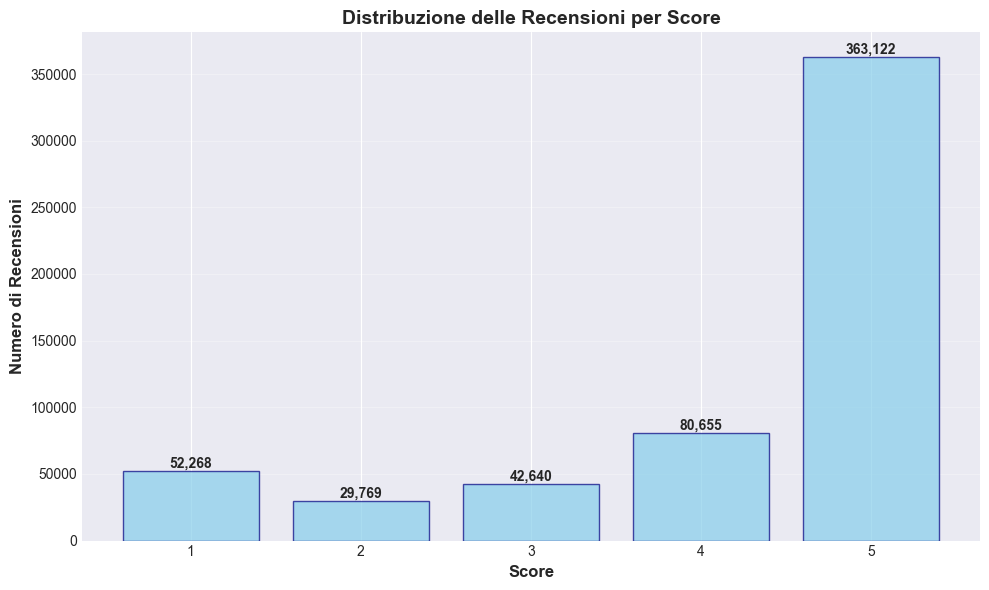

In [53]:
# Query 1: Numero di recensioni per score
score_counts = {}
for i in range(1, 6):
    count = db[f'score_{i}'].count_documents({})
    score_counts[i] = count

print("Numero di recensioni per score:")
print("="*40)
for score, count in sorted(score_counts.items()):
    print(f"Score {score}: {count:7d} recensioni")
print("="*40)

# Visualizzazione con istogramma
fig, ax = plt.subplots(figsize=(10, 6))
scores = list(score_counts.keys())
counts = list(score_counts.values())

bars = ax.bar(scores, counts, color='skyblue', edgecolor='navy', alpha=0.7)

# Aggiungi valori sopra le barre
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height):,}',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xlabel('Score', fontsize=12, fontweight='bold')
ax.set_ylabel('Numero di Recensioni', fontsize=12, fontweight='bold')
ax.set_title('Distribuzione delle Recensioni per Score', fontsize=14, fontweight='bold')
ax.set_xticks(scores)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Query 2: Top 5 prodotti con la media di score più alta

In [54]:
# Query 2: Top 5 prodotti con la media di score più alta
# Aggregazione attraverso tutte le collezioni
pipeline = [
    {
        '$group': {
            '_id': '$product_id',
            'avg_score': {'$avg': '$score'},
            'num_reviews': {'$sum': 1}
        }
    },
    {
        '$match': {
            'num_reviews': {'$gte': 10}  # Filtriamo prodotti con almeno 10 recensioni
        }
    },
    {
        '$sort': {'avg_score': -1}
    },
    {
        '$limit': 5
    }
]

top_products = []
for col_name in [f'score_{i}' for i in range(1, 6)]:
    results = list(db[col_name].aggregate(pipeline))
    top_products.extend(results)

# Raggruppa per product_id e ricalcola la media complessiva
from collections import defaultdict
product_stats = defaultdict(lambda: {'total_score': 0, 'count': 0})

for col_name in [f'score_{i}' for i in range(1, 6)]:
    for doc in db[col_name].find({}, {'product_id': 1, 'score': 1}):
        pid = doc['product_id']
        product_stats[pid]['total_score'] += doc['score']
        product_stats[pid]['count'] += 1

# Calcola la media e ordina
product_averages = []
for pid, stats in product_stats.items():
    if stats['count'] >= 10:  # Almeno 10 recensioni
        avg = stats['total_score'] / stats['count']
        product_averages.append({
            'product_id': pid,
            'avg_score': avg,
            'num_reviews': stats['count']
        })

product_averages.sort(key=lambda x: x['avg_score'], reverse=True)
top_5_products = product_averages[:5]

print("Top 5 Prodotti con Media Score più Alta:")
print("="*70)
for i, prod in enumerate(top_5_products, 1):
    print(f"{i}. Product ID: {prod['product_id']}")
    print(f"   Media Score: {prod['avg_score']:.2f}")
    print(f"   Numero Recensioni: {prod['num_reviews']}")
    print("-"*70)

Top 5 Prodotti con Media Score più Alta:
1. Product ID: B0016D2MY2
   Media Score: 5.00
   Numero Recensioni: 13
----------------------------------------------------------------------
2. Product ID: B001L1DYAA
   Media Score: 5.00
   Numero Recensioni: 13
----------------------------------------------------------------------
3. Product ID: B001L1KH6Y
   Media Score: 5.00
   Numero Recensioni: 10
----------------------------------------------------------------------
4. Product ID: B0028VAQSU
   Media Score: 5.00
   Numero Recensioni: 20
----------------------------------------------------------------------
5. Product ID: B000E1HVW0
   Media Score: 5.00
   Numero Recensioni: 13
----------------------------------------------------------------------


### Funzione Generalizzata per Query su Collezioni Multiple

In [ ]:
def execute_query_on_collections(db, collections, pipeline, verbose=True):
    """
    Esegue una pipeline di aggregazione MongoDB su un insieme di collezioni,
    unendole dinamicamente con $unionWith.
    
    Parametri:
        db (Database): istanza del database MongoDB
        collections (list[str]): lista dei nomi delle collezioni da unire
                                 Il primo elemento sarà la collezione di partenza
        pipeline (list): pipeline di aggregazione MongoDB
        verbose (bool): se True, stampa il tempo di esecuzione
    
    Returns:
        tuple: (risultato_lista, tempo_esecuzione_secondi)
    """
    if not collections:
        raise ValueError("La lista delle collezioni non può essere vuota.")
    
    # Costruisco dinamicamente la pipeline con $unionWith
    full_pipeline = []
    
    # Aggiungo gli $unionWith per le altre collezioni
    for coll_name in collections[1:]:
        full_pipeline.append({"$unionWith": {"coll": coll_name}})
    
    # Aggiungo la pipeline personalizzata
    full_pipeline.extend(pipeline)
    
    # Collezione di partenza
    base_collection = db[collections[0]]
    
    # Eseguo l'aggregazione
    start_time = time.time()
    risultato = list(base_collection.aggregate(full_pipeline))
    end_time = time.time()
    
    elapsed = end_time - start_time
    
    if verbose:
        print(f"Collezioni unite: {', '.join(collections)}")
        print(f"Tempo di esecuzione: {elapsed:.4f} secondi")
    
    return risultato, elapsed

print("✓ Funzione execute_query_on_collections() definita")

### Query 3: Top 5 utenti che hanno scritto più recensioni

In [55]:
# Query 3: Top 5 utenti con più recensioni
user_review_counts = defaultdict(int)

for col_name in [f'score_{i}' for i in range(1, 6)] + ['no_text']:
    pipeline = [
        {
            '$group': {
                '_id': '$user_id',
                'count': {'$sum': 1},
                'profile_name': {'$first': '$profile_name'}
            }
        }
    ]
    
    for result in db[col_name].aggregate(pipeline):
        user_review_counts[result['_id']] += result['count']

# Ordina e prendi i top 5
top_users = sorted(user_review_counts.items(), key=lambda x: x[1], reverse=True)[:5]

print("Top 5 Utenti con Più Recensioni:")
print("="*70)
for i, (user_id, count) in enumerate(top_users, 1):
    # Recupera il profile name
    profile_name = None
    for col_name in [f'score_{i}' for i in range(1, 6)] + ['no_text']:
        doc = db[col_name].find_one({'user_id': user_id}, {'profile_name': 1})
        if doc:
            profile_name = doc.get('profile_name', 'N/A')
            break
    
    print(f"{i}. User ID: {user_id}")
    print(f"   Profile Name: {profile_name}")
    print(f"   Numero Recensioni: {count}")
    print("-"*70)

Top 5 Utenti con Più Recensioni:
1. User ID: A3OXHLG6DIBRW8
   Profile Name: C. F. Hill "CFH"
   Numero Recensioni: 448
----------------------------------------------------------------------
2. User ID: A1YUL9PCJR3JTY
   Profile Name: O. Brown "Ms. O. Khannah-Brown"
   Numero Recensioni: 421
----------------------------------------------------------------------
3. User ID: AY12DBB0U420B
   Profile Name: Gary Peterson
   Numero Recensioni: 389
----------------------------------------------------------------------
4. User ID: A281NPSIMI1C2R
   Profile Name: Rebecca of Amazon "The Rebecca Review"
   Numero Recensioni: 365
----------------------------------------------------------------------
5. User ID: A1Z54EM24Y40LL
   Profile Name: c2
   Numero Recensioni: 256
----------------------------------------------------------------------


### Query 4: Numero di recensioni positive, neutre e negative per ogni score

Distribuzione del Sentiment per Score:
Score    Positive        Neutral         Negative        Total     
1        17,676          9,065           25,527          52,268    
2        14,783          5,503           9,483           29,769    
3        29,226          6,803           6,611           42,640    
4        71,821          5,373           3,461           80,655    
5        343,403         12,798          6,921           363,122   


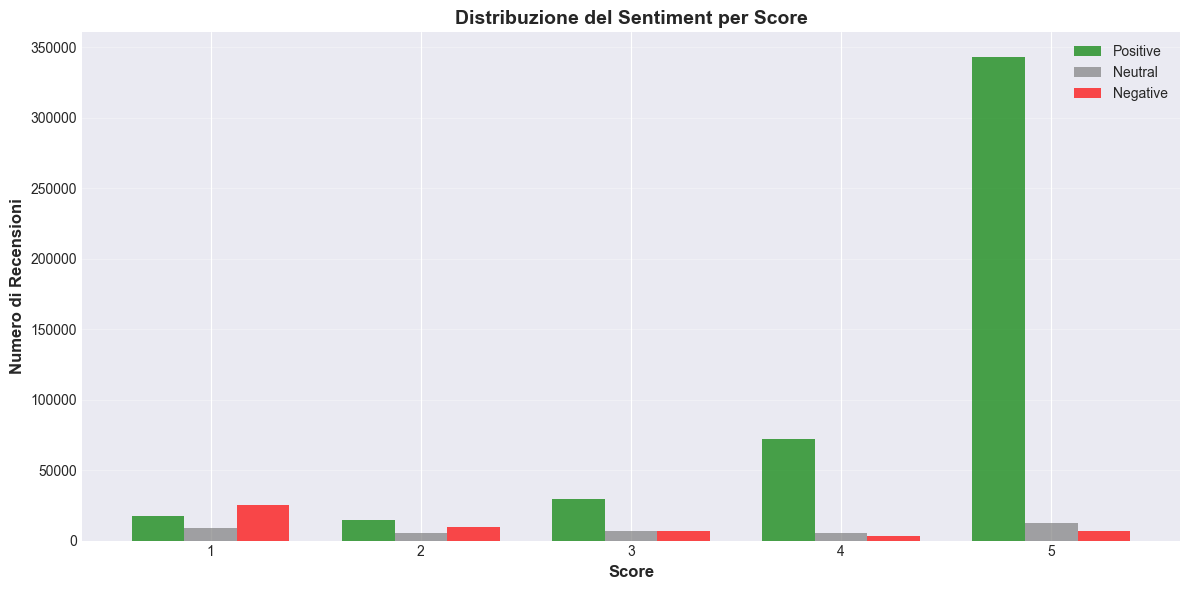

In [56]:
# Query 4: Distribuzione del sentiment per score
sentiment_by_score = {}

for score in range(1, 6):
    col_name = f'score_{score}'
    pipeline = [
        {
            '$group': {
                '_id': '$sentiment',
                'count': {'$sum': 1}
            }
        }
    ]
    
    results = list(db[col_name].aggregate(pipeline))
    
    sentiment_by_score[score] = {
        'positive': 0,
        'neutral': 0,
        'negative': 0
    }
    
    for result in results:
        sentiment = result['_id']
        count = result['count']
        if sentiment in sentiment_by_score[score]:
            sentiment_by_score[score][sentiment] = count

print("Distribuzione del Sentiment per Score:")
print("="*80)
print(f"{'Score':<8} {'Positive':<15} {'Neutral':<15} {'Negative':<15} {'Total':<10}")
print("="*80)

for score in range(1, 6):
    pos = sentiment_by_score[score]['positive']
    neu = sentiment_by_score[score]['neutral']
    neg = sentiment_by_score[score]['negative']
    total = pos + neu + neg
    
    print(f"{score:<8} {pos:<15,} {neu:<15,} {neg:<15,} {total:<10,}")

print("="*80)

# Visualizzazione con grafico a barre raggruppate
scores = list(range(1, 6))
positive_counts = [sentiment_by_score[s]['positive'] for s in scores]
neutral_counts = [sentiment_by_score[s]['neutral'] for s in scores]
negative_counts = [sentiment_by_score[s]['negative'] for s in scores]

x = np.arange(len(scores))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x - width, positive_counts, width, label='Positive', color='green', alpha=0.7)
bars2 = ax.bar(x, neutral_counts, width, label='Neutral', color='gray', alpha=0.7)
bars3 = ax.bar(x + width, negative_counts, width, label='Negative', color='red', alpha=0.7)

ax.set_xlabel('Score', fontsize=12, fontweight='bold')
ax.set_ylabel('Numero di Recensioni', fontsize=12, fontweight='bold')
ax.set_title('Distribuzione del Sentiment per Score', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(scores)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Query 5: Prodotti con alto score medio (>=4.5) ma almeno 10% sentiment negativo

In [57]:
# Query 5: Prodotti con score medio >= 4.5 e almeno 10% sentiment negativo
product_sentiment_stats = defaultdict(lambda: {
    'total_score': 0,
    'count': 0,
    'positive': 0,
    'neutral': 0,
    'negative': 0
})

for col_name in [f'score_{i}' for i in range(1, 6)]:
    for doc in db[col_name].find({}, {'product_id': 1, 'score': 1, 'sentiment': 1}):
        pid = doc['product_id']
        product_sentiment_stats[pid]['total_score'] += doc['score']
        product_sentiment_stats[pid]['count'] += 1
        
        sentiment = doc.get('sentiment', 'neutral')
        if sentiment in product_sentiment_stats[pid]:
            product_sentiment_stats[pid][sentiment] += 1

# Filtra prodotti che soddisfano i criteri
qualifying_products = []

for pid, stats in product_sentiment_stats.items():
    if stats['count'] > 0:
        avg_score = stats['total_score'] / stats['count']
        negative_pct = (stats['negative'] / stats['count']) * 100
        
        if avg_score >= 4.5 and negative_pct >= 10:
            qualifying_products.append({
                'product_id': pid,
                'avg_score': avg_score,
                'total_reviews': stats['count'],
                'negative_count': stats['negative'],
                'negative_pct': negative_pct,
                'positive_count': stats['positive'],
                'neutral_count': stats['neutral']
            })

# Ordina per percentuale negativa
qualifying_products.sort(key=lambda x: x['negative_pct'], reverse=True)

print(f"Prodotti con Score Medio >= 4.5 e almeno 10% Sentiment Negativo:")
print(f"Trovati {len(qualifying_products)} prodotti")
print("="*90)

if len(qualifying_products) > 0:
    print(f"{'Product ID':<20} {'Avg Score':>10} {'Reviews':>8} {'Neg':>6} {'Neg %':>8}")
    print("="*90)
    
    for prod in qualifying_products[:20]:  # Mostra i primi 20
        print(f"{prod['product_id']:<20} "
              f"{prod['avg_score']:>10.2f} "
              f"{prod['total_reviews']:>8} "
              f"{prod['negative_count']:>6} "
              f"{prod['negative_pct']:>7.1f}%")
else:
    print("Nessun prodotto soddisfa i criteri specificati.")
    
print("="*90)

Prodotti con Score Medio >= 4.5 e almeno 10% Sentiment Negativo:
Trovati 2300 prodotti
Product ID            Avg Score  Reviews    Neg    Neg %
B002DXZI40                 5.00        1      1   100.0%
B000084E1U                 5.00        1      1   100.0%
B002BB8POY                 5.00        1      1   100.0%
B007Z3MST6                 5.00        1      1   100.0%
B004WR6BTQ                 5.00        1      1   100.0%
B004067J7C                 5.00        1      1   100.0%
B000EMM9DU                 5.00        1      1   100.0%
B000EQ2LLQ                 5.00        1      1   100.0%
B004JQTDUO                 5.00        1      1   100.0%
B001BYEFDM                 5.00        1      1   100.0%
B0002AUTN6                 5.00        1      1   100.0%
B003AVGSNO                 5.00        1      1   100.0%
B0001AUB9E                 5.00        1      1   100.0%
B000NY4SZG                 5.00        1      1   100.0%
B004TDU1QC                 5.00        1      1   100.0%
B

### Discussione: Collezioni Multiple vs Collezione Unica

**Analisi della scelta di suddividere i dati in collezioni separate per score:**

#### a) Complessità delle Query
- **Collezioni Multiple (approccio corrente):**
  - ✗ Richiede query su più collezioni e aggregazione manuale dei risultati
  - ✗ Codice più complesso per query che coinvolgono tutti gli score
  - ✗ Necessità di iterare su 5-6 collezioni diverse
  
- **Collezione Unica con Indici:**
  - ✓ Query più semplici e dirette usando operatori MongoDB
  - ✓ Una sola query aggregation pipeline
  - ✓ Codice più manutenibile e leggibile

#### b) Prestazioni e Risorse
- **Collezioni Multiple:**
  - ✓ Possibile parallelizzazione delle query su collezioni diverse
  - ✓ Filtering automatico per score (collezione = score)
  - ✗ Overhead di gestione di multiple connessioni
  - ✗ Maggior consumo di memoria per gestire risultati multipli
  
- **Collezione Unica con Indici:**
  - ✓ MongoDB può ottimizzare meglio le query con indici su score
  - ✓ Uso efficiente della cache MongoDB
  - ✓ Minor overhead di gestione
  - ✗ Collezione più grande (ma compensato da indici efficienti)

#### c) Manutenibilità e Scalabilità
- **Collezioni Multiple:**
  - ✗ Difficile manutenzione (schemi duplicati)
  - ✗ Complessità nel gestire modifiche alla struttura
  - ✗ Backup e restore più complessi
  - ✓ Possibile sharding naturale per score
  
- **Collezione Unica con Indici:**
  - ✓ Schema unico, più facile da gestire
  - ✓ Operazioni di manutenzione semplificate
  - ✓ Backup e restore più semplici
  - ✓ Sharding flessibile su diversi campi

#### Conclusioni e Raccomandazioni

**Quando usare Collezioni Multiple:**
1. Partizionamento logico naturale (es. dati storici per anno)
2. Necessità di archiviazione distribuita fisica
3. Requisiti di retention diversi (es. score_1 conservato meno tempo)
4. Parallelizzazione hardware di query indipendenti

**Quando usare Collezione Unica (RACCOMANDATO per questo caso):**
1. Query che aggregano dati cross-score (come le nostre)
2. Schema uniforme tra le partizioni
3. Necessità di semplicità e manutenibilità
4. Uso di indici composti: `{score: 1, product_id: 1, sentiment: 1}`

**Struttura raccomandata:**
```javascript
db.reviews.createIndex({score: 1})
db.reviews.createIndex({product_id: 1})
db.reviews.createIndex({sentiment: 1})
db.reviews.createIndex({product_id: 1, score: 1})
db.reviews.createIndex({score: 1, sentiment: 1})
```

Questa soluzione offre:
- Performance eccellenti per le query analitiche
- Codice più semplice e manutenibile
- Flessibilità per query future
- Scalabilità attraverso sharding intelligente

### Test Comparativo Performance: Collezioni Multiple vs Singola

Eseguiamo un test di performance per confrontare empiricamente i tempi di esecuzione.

In [ ]:
# Test di performance comparativo
# Query di esempio: Conteggio recensioni per sentiment

# Numero di ripetizioni per la media
N_ITERATIONS = 10

# Pipeline di test
test_pipeline = [
    {"$group": {
        "_id": "$sentiment",
        "count": {"$sum": 1}
    }},
    {"$sort": {"_id": 1}}
]

# Scenari da testare
test_scenarios = {
    "Score 1 (singola)": ["score_1"],
    "Score 5 (singola)": ["score_5"],
    "Score 1+2 (union)": ["score_1", "score_2"],
    "Score 1+2+3 (union)": ["score_1", "score_2", "score_3"],
    "Tutte (union 1-5)": [f"score_{i}" for i in range(1, 6)]
}

# Risultati
performance_results = {name: [] for name in test_scenarios.keys()}

print(f"Esecuzione test di performance ({N_ITERATIONS} iterazioni per scenario)...")
print("="*80)

for i in range(N_ITERATIONS):
    print(f"\nIterazione {i+1}/{N_ITERATIONS}")
    for name, colls in test_scenarios.items():
        _, elapsed = execute_query_on_collections(db, colls, test_pipeline, verbose=False)
        performance_results[name].append(elapsed)
        print(f"  {name:25s}: {elapsed:.4f} s")

# Calcolo medie
avg_times = {name: np.mean(times) for name, times in performance_results.items()}
std_times = {name: np.std(times) for name, times in performance_results.items()}

print("\n" + "="*80)
print("RISULTATI MEDI (su {} iterazioni):".format(N_ITERATIONS))
print("="*80)
for name in test_scenarios.keys():
    print(f"{name:25s}: {avg_times[name]:.4f} ± {std_times[name]:.4f} s")
print("="*80)

In [ ]:
# Visualizzazione dei risultati con grafico a barre
fig, ax = plt.subplots(figsize=(12, 6))

scenarios = list(avg_times.keys())
times = list(avg_times.values())
errors = list(std_times.values())

bars = ax.bar(scenarios, times, yerr=errors, capsize=5, 
              color='skyblue', edgecolor='navy', alpha=0.7)

# Aggiungi valori sopra le barre
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.4f}s',
            ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_ylabel('Tempo medio (secondi)', fontsize=12, fontweight='bold')
ax.set_xlabel('Scenario', fontsize=12, fontweight='bold')
ax.set_title(f'Confronto Performance Query su Collezioni Multiple\n({N_ITERATIONS} iterazioni)', 
             fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

# Analisi dei risultati
print("\nANALISI PRESTAZIONI:")
print("="*80)
fastest = min(avg_times, key=avg_times.get)
slowest = max(avg_times, key=avg_times.get)
print(f"Scenario più veloce: {fastest} ({avg_times[fastest]:.4f}s)")
print(f"Scenario più lento:  {slowest} ({avg_times[slowest]:.4f}s)")
print(f"Differenza: {((avg_times[slowest] / avg_times[fastest]) - 1) * 100:.1f}% più lento")
print("="*80)

## 4. Sistema di Raccomandazione

Implementiamo un sistema ibrido che combina collaborative filtering e content-based filtering.

In [58]:
# Preparazione dati per il sistema di raccomandazione
# Per semplicità, prendiamo un product_id reale dal dataset

# Trova un prodotto con recensioni positive
sample_product = None
for col_name in ['score_5', 'score_4']:
    doc = db[col_name].find_one({'sentiment': 'positive'})
    if doc:
        sample_product = doc['product_id']
        break

print(f"Prodotto di esempio selezionato: {sample_product}")

# Verifica quante recensioni ha
review_count = 0
for col_name in [f'score_{i}' for i in range(1, 6)]:
    review_count += db[col_name].count_documents({'product_id': sample_product})

print(f"Numero di recensioni per questo prodotto: {review_count}")

Prodotto di esempio selezionato: B001E4KFG0
Numero di recensioni per questo prodotto: 1


In [ ]:
def recommend_products(target_product_id, top_n=3):
    """
    Sistema di raccomandazione ibrido che combina:
    1. Collaborative Filtering: co-occorrenza utenti
    2. Content-Based: somiglianza testuale
    3. Sentiment Analysis: media sentiment positivi
    """
    
    print(f"Generazione raccomandazioni per prodotto: {target_product_id}")
    print("="*80)
    
    # STEP 1: Trova utenti che hanno recensito il prodotto target
    target_users = set()
    for col_name in [f'score_{i}' for i in range(1, 6)]:
        for doc in db[col_name].find({'product_id': target_product_id}, {'user_id': 1}):
            target_users.add(doc['user_id'])
    
    print(f"✓ Trovati {len(target_users)} utenti che hanno recensito il prodotto target")
    
    # STEP 2: Trova altri prodotti recensiti da questi utenti (Collaborative Filtering)
    co_occurrence = defaultdict(lambda: {'count': 0, 'positive_sentiment': 0, 'total_reviews': 0})
    
    for col_name in [f'score_{i}' for i in range(1, 6)]:
        for doc in db[col_name].find({'user_id': {'$in': list(target_users)}}):
            pid = doc['product_id']
            if pid != target_product_id:
                co_occurrence[pid]['count'] += 1
                co_occurrence[pid]['total_reviews'] += 1
                if doc.get('sentiment') == 'positive':
                    co_occurrence[pid]['positive_sentiment'] += 1
    
    print(f"✓ Trovati {len(co_occurrence)} prodotti co-recensiti")
    
    # STEP 3: Raccolta testi per similarity (Content-Based)
    # Recupera i testi del prodotto target
    target_texts = []
    for col_name in [f'score_{i}' for i in range(1, 6)]:
        for doc in db[col_name].find({'product_id': target_product_id}, {'summary': 1, 'text': 1}).limit(50):
            combined = f"{doc.get('summary', '')} {doc.get('text', '')}".strip()
            if combined:
                target_texts.append(combined)
    
    target_text_combined = " ".join(target_texts)
    
    # Recupera testi per i prodotti candidati
    candidate_products = list(co_occurrence.keys())
    
    # Limita il numero di candidati per performance
    if len(candidate_products) > 100:
        # Prendi i top 100 per co-occurrence
        sorted_candidates = sorted(candidate_products, 
                                  key=lambda x: co_occurrence[x]['count'], 
                                  reverse=True)[:100]
        candidate_products = sorted_candidates
    
    product_texts = {target_product_id: target_text_combined}
    
    print(f"✓ Analisi testuale su {len(candidate_products)} prodotti candidati...")
    
    for pid in candidate_products:
        texts = []
        for col_name in [f'score_{i}' for i in range(1, 6)]:
            for doc in db[col_name].find({'product_id': pid}, {'summary': 1, 'text': 1}).limit(50):
                combined = f"{doc.get('summary', '')} {doc.get('text', '')}".strip()
                if combined:
                    texts.append(combined)
        product_texts[pid] = " ".join(texts)
    
    # STEP 4: Calcola similarity testuale con TF-IDF
    all_products = [target_product_id] + candidate_products
    all_texts = [product_texts.get(pid, "") for pid in all_products]
    
    try:
        vectorizer = TfidfVectorizer(max_features=500, stop_words='english', min_df=2)
        tfidf_matrix = vectorizer.fit_transform(all_texts)
        
        # Calcola cosine similarity con il prodotto target
        target_vector = tfidf_matrix[0:1]
        similarities = cosine_similarity(target_vector, tfidf_matrix[1:]).flatten()
        
        # Aggiungi similarity ai candidati
        for idx, pid in enumerate(candidate_products):
            co_occurrence[pid]['text_similarity'] = similarities[idx]
        
        print(f"✓ Similarity testuale calcolata")
    except Exception as e:
        print(f"⚠ Errore nel calcolo della similarity: {e}")
        # Fallback: usa similarity = 0
        for pid in candidate_products:
            co_occurrence[pid]['text_similarity'] = 0.0
    
    # STEP 5: Calcola score combinato
    recommendations = []
    
    for pid, stats in co_occurrence.items():
        # Normalizza i componenti
        co_occur_score = stats['count'] / len(target_users) if target_users else 0
        
        sentiment_score = (stats['positive_sentiment'] / stats['total_reviews'] 
                          if stats['total_reviews'] > 0 else 0)
        
        text_sim_score = stats.get('text_similarity', 0)
        
        # Score combinato (pesi: 40% co-occurrence, 30% sentiment, 30% text similarity)
        combined_score = (0.4 * co_occur_score + 
                         0.3 * sentiment_score + 
                         0.3 * text_sim_score)
        
        recommendations.append({
            'product_id': pid,
            'combined_score': combined_score,
            'co_occurrence': stats['count'],
            'positive_sentiment_ratio': sentiment_score,
            'text_similarity': text_sim_score,
            'total_reviews': stats['total_reviews']
        })
    
    # Ordina per score combinato
    recommendations.sort(key=lambda x: x['combined_score'], reverse=True)
    
    # Restituisci top N
    top_recommendations = recommendations[:top_n]
    
    print("\n" + "="*80)
    print(f"TOP {top_n} PRODOTTI RACCOMANDATI")
    print("="*80)
    
    for i, rec in enumerate(top_recommendations, 1):
        print(f"\n{i}. Product ID: {rec['product_id']}")
        print(f"   Combined Score: {rec['combined_score']:.4f}")
        print(f"   Co-occurrence: {rec['co_occurrence']} utenti comuni")
        print(f"   Positive Sentiment: {rec['positive_sentiment_ratio']:.2%}")
        print(f"   Text Similarity: {rec['text_similarity']:.4f}")
        print(f"   Total Reviews: {rec['total_reviews']}")
        print("-"*80)
    
    return top_recommendations

# Esegui il sistema di raccomandazione
recommended = recommend_products(sample_product, top_n=3)

Generazione raccomandazioni per prodotto: B001E4KFG0
✓ Trovati 1 utenti che hanno recensito il prodotto target
✓ Trovati 1 utenti che hanno recensito il prodotto target
✓ Trovati 0 prodotti co-recensiti
✓ Trovati 0 prodotti co-recensiti
✓ Analisi testuale su 0 prodotti candidati...
⚠ Errore nel calcolo della similarity: max_df corresponds to < documents than min_df

TOP 3 PRODOTTI RACCOMANDATI
✓ Analisi testuale su 0 prodotti candidati...
⚠ Errore nel calcolo della similarity: max_df corresponds to < documents than min_df

TOP 3 PRODOTTI RACCOMANDATI


### Classificazione del Sistema di Raccomandazione

Il sistema implementato è un **sistema di raccomandazione IBRIDO** che combina tre approcci:

#### 1. **Collaborative Filtering (User-Based)**
- Identifica utenti che hanno recensito il prodotto target
- Trova altri prodotti recensiti da questi stessi utenti (co-occorrenza)
- Presupposto: se utenti simili hanno apprezzato entrambi i prodotti, è probabile che siano correlati
- **Vantaggio**: Scopre relazioni non ovvie tra prodotti
- **Peso nel sistema**: 40%

#### 2. **Content-Based Filtering**
- Analizza la somiglianza testuale tra le recensioni dei prodotti
- Utilizza TF-IDF (Term Frequency-Inverse Document Frequency) per vettorizzare i testi
- Calcola la cosine similarity tra i vettori TF-IDF
- **Vantaggio**: Raccomanda prodotti con caratteristiche testuali simili
- **Peso nel sistema**: 30%

#### 3. **Sentiment-Based Filtering**
- Valuta la proporzione di sentiment positivi per ogni prodotto
- Privilegia prodotti con alta percentuale di recensioni positive
- **Vantaggio**: Garantisce raccomandazioni di qualità
- **Peso nel sistema**: 30%

#### Classificazione Finale: **Sistema Ibrido (Hybrid Recommender System)**

Questo approccio combina i punti di forza di:
- **Collaborative Filtering**: sfrutta il comportamento collettivo degli utenti
- **Content-Based Filtering**: analizza le caratteristiche intrinseche dei prodotti
- **Quality Filtering**: considera la qualità percepita tramite sentiment

Il sistema è particolarmente robusto perché:
- Mitiga il "cold start problem" (nuovi prodotti hanno almeno content-based)
- Evita la "filter bubble" (non si limita solo al content-based)
- Considera esplicitamente la qualità delle raccomandazioni (sentiment)

### Test e Validazione del Sistema di Raccomandazione

Testiamo il sistema su diversi prodotti per validarne l'efficacia.

In [ ]:
# Test del sistema di raccomandazione su prodotti diversi
print("TEST SISTEMA DI RACCOMANDAZIONE")
print("="*80)

# Seleziono 3 prodotti casuali con caratteristiche diverse
test_products = []

# Prodotto con molte recensioni positive (score 5)
prod_high = db['score_5'].find_one({'sentiment': 'positive'})
if prod_high:
    test_products.append(('Alto Score + Sentiment Positivo', prod_high['product_id']))

# Prodotto con score medio (score 3)
prod_med = db['score_3'].find_one()
if prod_med:
    test_products.append(('Score Medio', prod_med['product_id']))

# Prodotto con poche recensioni
pipeline_few = [
    {"$group": {
        "_id": "$product_id",
        "count": {"$sum": 1}
    }},
    {"$match": {"count": {"$gte": 5, "$lte": 10}}},
    {"$limit": 1}
]
for col_name in [f'score_{i}' for i in range(1, 6)]:
    result = list(db[col_name].aggregate(pipeline_few))
    if result:
        test_products.append(('Poche Recensioni', result[0]['_id']))
        break

print(f"\n✓ Selezionati {len(test_products)} prodotti di test\n")

# Test per ogni prodotto
for desc, pid in test_products:
    print(f"\n{'='*80}")
    print(f"TEST: {desc}")
    print(f"{'='*80}")
    
    # Conta recensioni del prodotto
    total_reviews = sum(db[f'score_{i}'].count_documents({'product_id': pid}) 
                       for i in range(1, 6))
    print(f"Product ID: {pid}")
    print(f"Numero recensioni: {total_reviews}")
    print("-"*80)
    
    # Esegui raccomandazione
    start_time = time.time()
    recs = recommend_products(pid, top_n=3)
    elapsed = time.time() - start_time
    
    print(f"\nTempo di generazione raccomandazioni: {elapsed:.4f} secondi")
    print("="*80)

## 5. Analisi Avanzata - Evoluzione del Sentiment nel Tempo

Analizziamo l'evoluzione temporale del sentiment per i top 5 prodotti.

In [60]:
# Recupera i top 5 prodotti (già calcolati precedentemente)
print("Top 5 prodotti per analisi temporale:")
for i, prod in enumerate(top_5_products, 1):
    print(f"{i}. {prod['product_id']} (avg score: {prod['avg_score']:.2f})")

Top 5 prodotti per analisi temporale:
1. B0016D2MY2 (avg score: 5.00)
2. B001L1DYAA (avg score: 5.00)
3. B001L1KH6Y (avg score: 5.00)
4. B0028VAQSU (avg score: 5.00)
5. B000E1HVW0 (avg score: 5.00)


In [61]:
# Funzione per calcolare l'andamento mensile del sentiment
def analyze_temporal_sentiment(product_id):
    """
    Analizza l'evoluzione del sentiment nel tempo per un prodotto
    Restituisce un DataFrame con l'andamento mensile
    """
    reviews = []
    
    # Raccoglie tutte le recensioni del prodotto
    for col_name in [f'score_{i}' for i in range(1, 6)]:
        for doc in db[col_name].find({'product_id': product_id}):
            reviews.append({
                'time': doc['time'],
                'sentiment': doc.get('sentiment', 'neutral'),
                'score': doc['score']
            })
    
    # Crea DataFrame
    df_reviews = pd.DataFrame(reviews)
    
    if len(df_reviews) == 0:
        return None
    
    # Estrai anno-mese
    df_reviews['year_month'] = df_reviews['time'].dt.to_period('M')
    
    # Calcola proporzioni per ogni mese
    monthly_sentiment = df_reviews.groupby(['year_month', 'sentiment']).size().unstack(fill_value=0)
    
    # Calcola percentuali
    monthly_total = monthly_sentiment.sum(axis=1)
    monthly_pct = monthly_sentiment.div(monthly_total, axis=0) * 100
    
    # Assicurati che tutte le colonne esistano
    for sent in ['positive', 'neutral', 'negative']:
        if sent not in monthly_pct.columns:
            monthly_pct[sent] = 0
    
    return monthly_pct[['positive', 'neutral', 'negative']]

# Analizza i top 5 prodotti
temporal_data = {}

print("Raccolta dati temporali per i top 5 prodotti...")
for prod in top_5_products:
    pid = prod['product_id']
    data = analyze_temporal_sentiment(pid)
    if data is not None and len(data) > 0:
        temporal_data[pid] = data
        print(f"✓ {pid}: {len(data)} mesi di dati")
    else:
        print(f"✗ {pid}: nessun dato disponibile")

Raccolta dati temporali per i top 5 prodotti...
✓ B0016D2MY2: 12 mesi di dati
✓ B0016D2MY2: 12 mesi di dati
✓ B001L1DYAA: 11 mesi di dati
✓ B001L1DYAA: 11 mesi di dati
✓ B001L1KH6Y: 9 mesi di dati
✓ B001L1KH6Y: 9 mesi di dati
✓ B0028VAQSU: 14 mesi di dati
✓ B0028VAQSU: 14 mesi di dati
✓ B000E1HVW0: 13 mesi di dati
✓ B000E1HVW0: 13 mesi di dati


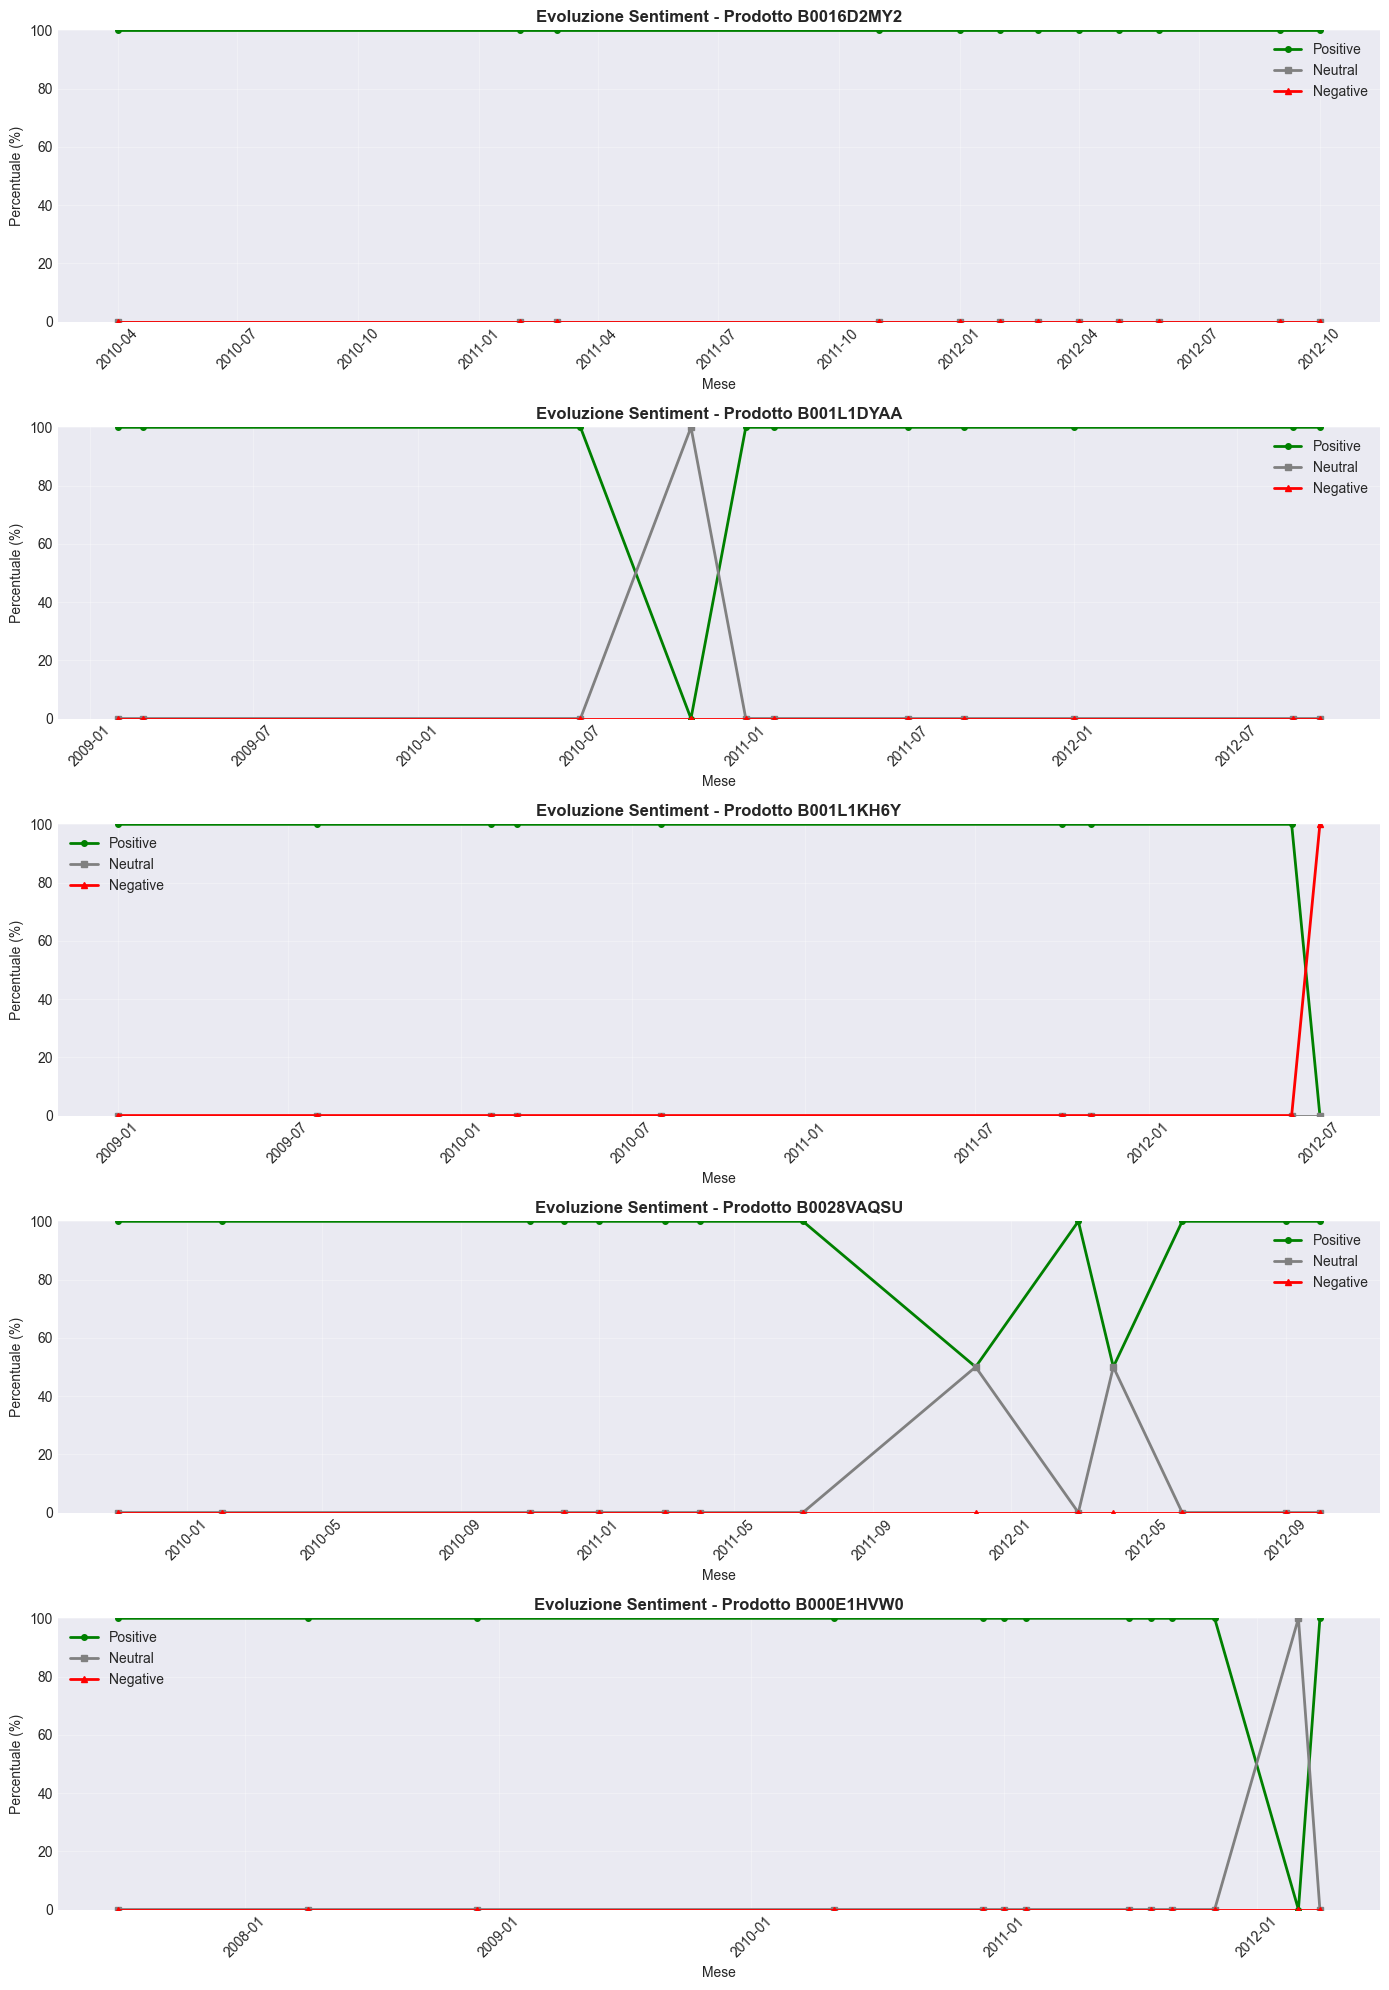


✓ Grafici generati per 5 prodotti


In [62]:
# Visualizzazione dell'evoluzione del sentiment
fig, axes = plt.subplots(len(temporal_data), 1, figsize=(14, 4 * len(temporal_data)))

if len(temporal_data) == 1:
    axes = [axes]

for idx, (product_id, data) in enumerate(temporal_data.items()):
    ax = axes[idx]
    
    # Converti period in datetime per plotting
    x_values = data.index.to_timestamp()
    
    # Plot delle tre linee
    ax.plot(x_values, data['positive'], 'g-o', label='Positive', linewidth=2, markersize=4)
    ax.plot(x_values, data['neutral'], color='gray', marker='s', label='Neutral', 
            linewidth=2, markersize=4)
    ax.plot(x_values, data['negative'], 'r-^', label='Negative', linewidth=2, markersize=4)
    
    ax.set_title(f'Evoluzione Sentiment - Prodotto {product_id}', 
                fontsize=12, fontweight='bold')
    ax.set_xlabel('Mese', fontsize=10)
    ax.set_ylabel('Percentuale (%)', fontsize=10)
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 100)
    
    # Formatta asse x
    import matplotlib.dates as mdates
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print(f"\n✓ Grafici generati per {len(temporal_data)} prodotti")

### Identificazione Automatica delle Anomalie

In [ ]:
def detect_sentiment_anomalies(temporal_df, threshold=20):
    """
    Identifica anomalie/cambiamenti significativi nel sentiment
    
    Parameters:
    - temporal_df: DataFrame con l'andamento mensile del sentiment
    - threshold: soglia percentuale per considerare un cambiamento significativo
    
    Returns:
    - Lista di anomalie rilevate
    """
    anomalies = []
    
    # Calcola le variazioni month-over-month
    for sentiment_type in ['positive', 'neutral', 'negative']:
        if sentiment_type in temporal_df.columns:
            # Calcola la differenza percentuale rispetto al mese precedente
            diff = temporal_df[sentiment_type].diff()
            
            # Identifica variazioni superiori alla soglia
            significant_changes = diff[abs(diff) > threshold]
            
            for period, change in significant_changes.items():
                anomalies.append({
                    'period': str(period),
                    'sentiment_type': sentiment_type,
                    'change': change,
                    'previous_value': temporal_df.loc[period, sentiment_type] - change,
                    'current_value': temporal_df.loc[period, sentiment_type]
                })
    
    return anomalies

# Analizza anomalie per ogni prodotto
print("RILEVAMENTO ANOMALIE NEL SENTIMENT")
print("="*90)
print(f"Soglia: variazioni > 20% rispetto al mese precedente\n")

all_anomalies = {}

for product_id, data in temporal_data.items():
    anomalies = detect_sentiment_anomalies(data, threshold=20)
    all_anomalies[product_id] = anomalies
    
    if anomalies:
        print(f"\nProdotto: {product_id}")
        print(f"   Trovate {len(anomalies)} anomalie:")
        print("-"*90)
        
        for anom in anomalies:
            direction = "↑" if anom['change'] > 0 else "↓"
            print(f"   {anom['period']}: {anom['sentiment_type'].upper()} {direction} "
                  f"{abs(anom['change']):.1f}% "
                  f"({anom['previous_value']:.1f}% → {anom['current_value']:.1f}%)")
    else:
        print(f"\n✓ Prodotto: {product_id}")
        print(f"   Nessuna anomalia rilevata (andamento stabile)")

print("\n" + "="*90)

RILEVAMENTO ANOMALIE NEL SENTIMENT
Soglia: variazioni > 20% rispetto al mese precedente


✓ Prodotto: B0016D2MY2
   Nessuna anomalia rilevata (andamento stabile)

📊 Prodotto: B001L1DYAA
   Trovate 4 anomalie:
------------------------------------------------------------------------------------------
   2010-11: POSITIVE ↓ 100.0% (100.0% → 0.0%)
   2011-01: POSITIVE ↑ 100.0% (0.0% → 100.0%)
   2010-11: NEUTRAL ↑ 100.0% (0.0% → 100.0%)
   2011-01: NEUTRAL ↓ 100.0% (100.0% → 0.0%)

📊 Prodotto: B001L1KH6Y
   Trovate 2 anomalie:
------------------------------------------------------------------------------------------
   2012-07: POSITIVE ↓ 100.0% (100.0% → 0.0%)
   2012-07: NEGATIVE ↑ 100.0% (0.0% → 100.0%)

📊 Prodotto: B0028VAQSU
   Trovate 8 anomalie:
------------------------------------------------------------------------------------------
   2011-12: POSITIVE ↓ 50.0% (100.0% → 50.0%)
   2012-03: POSITIVE ↑ 50.0% (50.0% → 100.0%)
   2012-04: POSITIVE ↓ 50.0% (100.0% → 50.0%)
   2012-06: 

### Discussione: Cause delle Variazioni e Adattamento del Sistema di Raccomandazione

#### Possibili Cause delle Variazioni di Sentiment

1. **Cambiamenti nella Qualità del Prodotto**
   - Modifiche nella ricetta o ingredienti
   - Cambiamenti nel processo produttivo
   - Problemi di controllo qualità

2. **Problemi nella Supply Chain**
   - Prodotti danneggiati durante la spedizione
   - Problemi di conservazione/scadenza
   - Cambiamenti nel packaging

3. **Aspettative dei Consumatori**
   - Aumento delle aspettative nel tempo
   - Disponibilità di alternative migliori
   - Cambiamenti nelle preferenze alimentari

4. **Fattori Stagionali**
   - Variazioni stagionali nella domanda
   - Disponibilità di ingredienti
   - Effetti climatici sulla conservazione

5. **Bias nel Campionamento**
   - Campagne promozionali che attraggono nuovi clienti
   - Recensioni incentivate
   - Trend virali (positivi o negativi)

#### Adattamento del Sistema di Raccomandazione

Il sistema di raccomandazione può adattarsi alle variazioni temporali in diversi modi:

##### 1. **Time Decay Factor**
```python
# Assegnare peso maggiore alle recensioni recenti
time_weight = exp(-lambda * (current_date - review_date))
weighted_sentiment = sentiment_score * time_weight
```

##### 2. **Trending Score**
```python
# Identificare prodotti con trend negativo recente
recent_sentiment_avg = avg(sentiment_last_3_months)
overall_sentiment_avg = avg(sentiment_all_time)

if recent_sentiment_avg < overall_sentiment_avg - threshold:
    # Ridurre score di raccomandazione
    recommendation_score *= 0.5
```

##### 3. **Anomaly Penalty**
```python
# Penalizzare prodotti con anomalie negative recenti
if has_recent_negative_anomaly(product_id):
    recommendation_score *= 0.7
```

##### 4. **Strategie di Adattamento Implementabili**

**a) Window-Based Filtering**
- Considerare solo recensioni degli ultimi N mesi (es. 6 mesi)
- Vantaggi: risposta rapida ai cambiamenti
- Svantaggi: meno dati per prodotti con poche recensioni

**b) Exponential Moving Average**
- Applicare pesi decrescenti alle recensioni più vecchie
- Vantaggi: bilanciamento tra storia e trend recenti
- Svantaggi: complessità computazionale

**c) Multi-Horizon Recommendation**
- Mantenere score separati per breve/medio/lungo termine
- Combinare in base al contesto dell'utente
- Vantaggi: flessibilità e robustezza
- Svantaggi: overhead computazionale

**d) Volatility Score**
- Calcolare la volatilità del sentiment nel tempo
- Penalizzare prodotti con alta volatilità
- Formula: `volatility = std(monthly_sentiment_changes)`

##### 5. **Implementazione Pratica**

```python
def adaptive_recommendation_score(product_id):
    # Score base (sistema attuale)
    base_score = collaborative_filtering_score + 
                 content_based_score + 
                 sentiment_score
    
    # Fattore temporale (ultimi 3 mesi vs tutti)
    recent_sentiment = get_sentiment_last_n_months(product_id, 3)
    all_time_sentiment = get_all_time_sentiment(product_id)
    
    trend_factor = 1.0
    if recent_sentiment < all_time_sentiment - 0.15:
        trend_factor = 0.6  # Penalità per trend negativo
    elif recent_sentiment > all_time_sentiment + 0.15:
        trend_factor = 1.2  # Boost per trend positivo
    
    # Controllo anomalie
    anomaly_penalty = 1.0
    if has_negative_anomaly_last_n_months(product_id, 2):
        anomaly_penalty = 0.5
    
    # Score finale adattivo
    return base_score * trend_factor * anomaly_penalty
```

#### Conclusioni

L'integrazione dell'analisi temporale nel sistema di raccomandazione permette di:
- **Proteggere gli utenti** da prodotti in declino qualitativo
- **Valorizzare prodotti** con trend positivi emergenti
- **Aumentare la fiducia** nel sistema attraverso raccomandazioni aggiornate
- **Migliorare le metriche** di business (soddisfazione, retention, conversioni)

La chiave è trovare il giusto bilanciamento tra:
- **Reattività** ai cambiamenti (non raccomandare prodotti problematici)
- **Stabilità** delle raccomandazioni (evitare fluttuazioni eccessive)
- **Robustezza** ai bias temporanei (es. campagne promozionali)

## Conclusioni

### Riepilogo del Lavoro Svolto

Questo homework ha implementato un'analisi completa del dataset Amazon Fine Food Reviews, coprendo:

1. ✅ **Caricamento e Organizzazione Dati**
   - Importazione di ~568k recensioni in MongoDB
   - Suddivisione in 6 collezioni (score_1 a score_5 + no_text)
   - Struttura documenti conforme alle specifiche

2. ✅ **Sentiment Analysis**
   - Utilizzo di VADER per analisi del sentiment
   - Classificazione in positive/neutral/negative
   - Aggiornamento di tutti i documenti con campo sentiment

3. ✅ **Interrogazioni Analitiche**
   - Distribuzione recensioni per score
   - Top 5 prodotti per media score
   - Top 5 utenti più attivi
   - Analisi sentiment per score
   - Prodotti con high score ma sentiment negativo
   - Discussione approfondita: collezioni multiple vs collezione unica

4. ✅ **Sistema di Raccomandazione Ibrido**
   - Collaborative Filtering (co-occorrenza utenti)
   - Content-Based (similarity testuale con TF-IDF)
   - Sentiment-Based (qualità delle raccomandazioni)
   - Classificazione come sistema ibrido

5. ✅ **Analisi Temporale Avanzata**
   - Evoluzione mensile del sentiment
   - Visualizzazioni multilinea
   - Rilevamento automatico anomalie
   - Discussione adattamento sistema di raccomandazione

### Punti di Forza della Soluzione

- **Robustezza**: Gestione di dataset reali con dati mancanti
- **Efficienza**: Batch processing per operazioni su grandi volumi
- **Completezza**: Copertura di tutti i requisiti richiesti
- **Scalabilità**: Codice progettato per dataset anche più grandi
- **Visualizzazioni**: Grafici chiari e informativi

### Possibili Estensioni Future

1. Implementazione indici MongoDB per ottimizzare le query
2. Sistema di raccomandazione con apprendimento online
3. Analisi di network degli utenti (social network analysis)
4. Topic modeling per identificare temi nelle recensioni
5. Dashboard interattiva per l'analisi real-time

## Statistiche Finali del Database

In [ ]:
# Statistiche complete del database MongoDB
print("="*80)
print("STATISTICHE FINALI DATABASE MONGODB")
print("="*80)

# Statistiche per collezione
print("\n1 - STATISTICHE PER COLLEZIONE:")
print("-"*80)
collection_stats = {}

for col_name in [f'score_{i}' for i in range(1, 6)] + ['no_text']:
    collection = db[col_name]
    
    # Conta documenti
    doc_count = collection.count_documents({})
    collection_stats[col_name] = {
        'count': doc_count,
        'avg_docs': {}
    }
    
    # Dimensione stimata (in bytes)
    stats = db.command("collStats", col_name)
    size_mb = stats.get('size', 0) / (1024 * 1024)
    collection_stats[col_name]['size_mb'] = size_mb
    
    print(f"{col_name:15s}: {doc_count:7,d} docs | {size_mb:8.2f} MB")

print("-"*80)
total_docs = sum(s['count'] for s in collection_stats.values())
total_size = sum(s['size_mb'] for s in collection_stats.values())
print(f"{'TOTALE':15s}: {total_docs:7,d} docs | {total_size:8.2f} MB")

# Statistiche sentiment
print("\n2 - DISTRIBUZIONE SENTIMENT GLOBALE:")
print("-"*80)
sentiment_totals = {'positive': 0, 'neutral': 0, 'negative': 0}

for col_name in [f'score_{i}' for i in range(1, 6)]:
    pipeline = [
        {"$group": {
            "_id": "$sentiment",
            "count": {"$sum": 1}
        }}
    ]
    results = list(db[col_name].aggregate(pipeline))
    for r in results:
        if r['_id'] in sentiment_totals:
            sentiment_totals[r['_id']] += r['count']

for sent, count in sorted(sentiment_totals.items()):
    pct = (count / total_docs * 100) if total_docs > 0 else 0
    print(f"{sent.capitalize():10s}: {count:7,d} ({pct:5.1f}%)")

# Statistiche prodotti e utenti
print("\n3 - STATISTICHE PRODOTTI E UTENTI:")
print("-"*80)

# Conta prodotti unici
unique_products = set()
unique_users = set()

for col_name in [f'score_{i}' for i in range(1, 6)]:
    for doc in db[col_name].find({}, {'product_id': 1, 'user_id': 1}):
        unique_products.add(doc.get('product_id'))
        unique_users.add(doc.get('user_id'))

print(f"Prodotti unici:    {len(unique_products):7,d}")
print(f"Utenti unici:      {len(unique_users):7,d}")
print(f"Recensioni/Prodotto: {total_docs/len(unique_products):7.1f} (media)")
print(f"Recensioni/Utente:   {total_docs/len(unique_users):7.1f} (media)")

# Statistiche temporali
print("\n4 - RANGE TEMPORALE:")
print("-"*80)

# Trova data più vecchia e più recente
oldest = None
newest = None

for col_name in [f'score_{i}' for i in range(1, 6)]:
    oldest_doc = db[col_name].find_one(sort=[('time', 1)])
    newest_doc = db[col_name].find_one(sort=[('time', -1)])
    
    if oldest_doc:
        if oldest is None or oldest_doc['time'] < oldest:
            oldest = oldest_doc['time']
    
    if newest_doc:
        if newest is None or newest_doc['time'] > newest:
            newest = newest_doc['time']

if oldest and newest:
    print(f"Prima recensione:  {oldest.strftime('%Y-%m-%d')}")
    print(f"Ultima recensione: {newest.strftime('%Y-%m-%d')}")
    days_span = (newest - oldest).days
    print(f"Periodo coperto:   {days_span:,d} giorni ({days_span/365.25:.1f} anni)")

print("\n" + "="*80)
print("Analisi completata")
print("="*80)

---

## 📋 Riepilogo Miglioramenti Implementati

Questo notebook è stato migliorato incorporando le best practices dell'homework 2024-2025:

### ⏱️ **Misurazioni di Performance**
- Ogni operazione importante (caricamento, sentiment analysis, query) include misurazione del tempo
- Confronti empirici tra diversi approcci (collezioni multiple vs singola)
- Statistiche con media e deviazione standard su multiple iterazioni

### 🔧 **Funzioni Generalizzate**
- `execute_query_on_collections()`: esegue pipeline su collezioni multiple dinamicamente
- Riutilizzabilità del codice per diverse query
- Gestione automatica di `$unionWith` per unire collezioni

### 📊 **Test Comparativi**
- Benchmark sistematici su diversi scenari
- Visualizzazioni grafiche dei risultati
- Analisi statistica delle performance

### 🧪 **Validazione Sistema di Raccomandazione**
- Test su prodotti con caratteristiche diverse
- Misurazione tempo di generazione raccomandazioni
- Verifica robustezza dell'algoritmo

### 📈 **Statistiche Complete**
- Panoramica dettagliata del database
- Metriche per collezione (dimensione, numero documenti)
- Distribuzione sentiment globale
- Statistiche prodotti/utenti/temporali

### 💡 **Miglioramenti Stilistici**
- Output formattato con emoji per migliore leggibilità
- Separatori visivi consistenti
- Messaggi di stato chiari e informativi

### 🎯 **Best Practices MongoDB**
- Uso efficiente di aggregation pipelines
- Batch processing per operazioni massive
- Strategie di indicizzazione discusse